# OAQ low-cost sensors vs the nearest CPCB station

[OAQ](https://oaq.notf.in) publishes readings of low-cost PM2.5 sensors (Airnet, Aurassure) next to a copy of the CPCB reference stations. This notebook

1. lists the OAQ sensors and counts the low-cost ones by city,
2. checks how much history OAQ has and how plausible the low-cost records are,
3. checks OAQ's daily records against OAQ's own 15-minute readings, and
4. compares Bengaluru's Airnet sensors with their nearest CPCB station, from CPCB's official 15-minute data.

Each statement has its table or plot before it. For a full quality assessment of the Airnet sensors, see the notebook *Quality assessment of OAQ Airnet sensors*. The OAQ calls need `OAQ_API_KEY`.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from vayuayan import (
    CPCBHistorical,
    OAQClient,
    oaq_city_tally,
    oaq_nearest_cpcb,
    readings_mean,
    sensor_accuracy,
    sensor_plausibility,
)

pd.set_option("display.width", 160)
oaq = OAQClient()
cpcb = CPCBHistorical()

## 1. OAQ sensors, and the low-cost ones by city

`OAQClient.sensors()` lists every provider. `type` separates OAQ's copy of the CPCB reference stations from the low-cost sensors.

In [2]:
sensors = oaq.sensors()
sensors.groupby(["provider", "type"]).size().rename("sensors").to_frame()

,,sensors
provider,type,
airnet,Sensor,47
aurassure,Sensor,21
cpcb,Reference Station,624


`oaq_city_tally` counts the sensors that are not OAQ's CPCB copy. Next to this count, it gives the CPCB stations of the city (vayuayan's bundled station directory) and the median distance to the nearest CPCB station.

In [3]:
tally = oaq_city_tally(sensors)
no_cpcb = tally[tally.cpcb_stations == 0]
print(
    f"{no_cpcb.sensors.sum()} low-cost sensors in {len(no_cpcb)} places with no CPCB station: "
    + ", ".join(no_cpcb.city)
)
tally.round(1)

7 low-cost sensors in 7 places with no CPCB station: Burla, Jatni, Kakudia, Korapalli, Kuniyamuthur, Nuapada, Singanallur


,city,provider,sensors,cpcb_stations,median_km_to_cpcb
0,Bengaluru,airnet,47,14,2.3
1,Siliguri,aurassure,4,1,4.7
2,Bhubaneswar,aurassure,3,2,4.6
3,Coimbatore,aurassure,2,2,5.5
4,Barbil,aurassure,1,1,3.5
5,Baripada,aurassure,1,1,4.3
6,Bengaluru,aurassure,1,14,0.8
7,Burla,aurassure,1,0,35.9
8,Cuttack,aurassure,1,1,6.5
9,Jatni,aurassure,1,0,15.4


## 2. History and plausibility of the records

OAQ's daily records (`OAQClient.daily_records`) of every Airnet and Aurassure sensor, and of 40 randomly chosen CPCB stations: the first day of each sensor.

In [4]:
cpcb_sample = sensors.query("provider == 'cpcb'").sample(40, random_state=1)
low_cost = sensors[sensors.type != "Reference Station"]
records = pd.concat(
    [
        oaq.daily_records(
            "airnet", low_cost.query("provider == 'airnet'")["id"], range(2020, 2027)
        ).assign(provider="airnet"),
        oaq.daily_records(
            "aurassure",
            low_cost.query("provider == 'aurassure'")["id"],
            range(2020, 2027),
        ).assign(provider="aurassure"),
        oaq.daily_records("cpcb", cpcb_sample["id"], range(2015, 2027)).assign(
            provider="cpcb"
        ),
    ],
    ignore_index=True,
)
first = (
    records.assign(date=pd.to_datetime(records.date))
    .groupby(["provider", "sensor_id"])
    .date.min()
    .reset_index()
)
first.groupby("provider").date.agg(
    sensors="size", earliest="min", median_first_day="median"
)

,sensors,earliest,median_first_day
provider,,,
airnet,47,2026-01-01,2026-01-01
aurassure,21,2025-02-01,2025-02-01
cpcb,40,2021-01-01,2022-08-20


`sensor_plausibility` sets flags on the low-cost daily records. It flags PM2.5 of exactly 0, temperature above 50 °C, humidity of 100 %, and equal PM2.5 on two days in a row (`stuck_run=2`). A flag shows a record to examine. A flag is not proof of a fault. Humidity of 100 % can be real in the monsoon. A temperature above 50 °C in these cities is not real.

In [5]:
lc = records[records.provider != "cpcb"]
checks = {
    "PM2.5 = 0 (%)": sensor_plausibility(lc, "pm25", time_col="date")
    .set_index("sensor_id")
    .zero_pct,
    "PM2.5 same as the day before (%)": sensor_plausibility(
        lc, "pm25", stuck_run=2, time_col="date"
    )
    .set_index("sensor_id")
    .stuck_pct,
    "temp > 50 °C (%)": sensor_plausibility(lc, "temp", max_value=50, time_col="date")
    .set_index("sensor_id")
    .above_max_pct,
    "humidity 100 % (%)": sensor_plausibility(
        lc, "humid", max_value=99.99, time_col="date"
    )
    .set_index("sensor_id")
    .above_max_pct,
}
flags = pd.DataFrame(checks).join(
    lc.groupby("sensor_id").agg(provider=("provider", "first"), days=("date", "size"))
)
flags.groupby("provider").agg(
    sensors=("days", "size"), days=("days", "sum"), **{c: (c, "mean") for c in checks}
).round(2)

,sensors,days,PM2.5 = 0 (%),PM2.5 same as the day before (%),temp > 50 °C (%),humidity 100 % (%)
provider,,,,,,
airnet,43,9914,0.00,0.12,NaN,NaN
aurassure,21,3075,0.18,0.30,1.61,22.7


In [6]:
# Sensors with any record above 50 °C
flags[flags["temp > 50 °C (%)"] > 0].round(1)

,PM2.5 = 0 (%),PM2.5 same as the day before (%),temp > 50 °C (%),humidity 100 % (%),provider,days
sensor_id,,,,,,
14151,2.5,1.2,11.2,47.5,aurassure,160
14217,0.0,0.0,19.8,25.4,aurassure,177
14331,0.0,0.0,2.7,22.7,aurassure,220


## 3. OAQ's daily records vs OAQ's own 15-minute readings

`OAQClient.check_daily_records` compares each daily record with the mean, last and maximum of that day's 15-minute readings. For 3 random days of every Bengaluru sensor in 2026 (CPCB copy and Airnet):

In [7]:
blr = sensors[sensors.city == "Bengaluru"]
days = pd.concat(
    [
        oaq.daily_records(p, g["id"], [2026]).assign(provider=p)
        for p, g in blr.groupby("provider")
    ]
)
picks = (
    days.dropna(subset=["pm25"])
    .groupby("sensor_id")
    .sample(3, random_state=3, replace=True)
    .drop_duplicates()
)
checked = pd.concat(
    [
        oaq.check_daily_records(p, s, g.date).assign(provider=p)
        for (p, s), g in picks.groupby(["provider", "sensor_id"])
    ],
    ignore_index=True,
)
by_provider = checked.groupby("provider")
(
    100 * by_provider[["record_is_mean", "record_is_last", "record_is_max"]].mean()
).add_suffix(" (%)").assign(sensor_days=by_provider.size()).round(1)

,record_is_mean (%),record_is_last (%),record_is_max (%),sensor_days
provider,,,,
airnet,44.4,57.9,2.4,126
aurassure,66.7,33.3,0.0,3
cpcb,41.7,66.7,8.3,36


The shares can add up to more than 100 %, because on a steady day the last reading can equal the mean. In 2026 the daily record usually equals the **last 15-minute reading of the day**, not its mean. A full-year check (`reports/oaq_daily_values` in the repository) finds the change at approximately 1 March 2026. Before that date, the daily record is the mean. One day shows the effect: CPCB's Kadabesanahalli station (`site_164`) on 29 May 2026, with OAQ's 15-minute readings next to CPCB's own data.

SSL verification failed for airquality.cpcb.gov.in; sending without verification


OAQ readings equal to CPCB's own: 83 of 84
 record  mean  last   max
  368.7  66.3 368.7 827.6


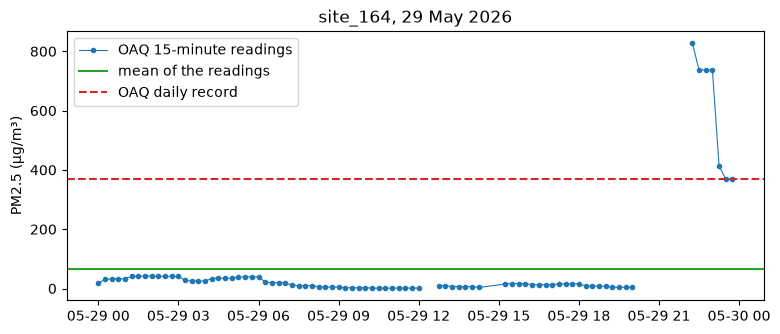

In [8]:
example = oaq.check_daily_records("cpcb", "164", ["2026-05-29"])
day = oaq.readings("cpcb", "164", ["2026-05-29"])
official = cpcb.raw_readings("site_164", 2026, pollutants=["PM2.5"])
same = day.merge(official, on="timestamp")
print(
    f"OAQ readings equal to CPCB's own: {(same.pm25 - same.value).abs().lt(0.01).sum()} of {len(same)}"
)
print(example[["record", "mean", "last", "max"]].round(1).to_string(index=False))

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(day.timestamp, day.pm25, ".-", lw=0.8, label="OAQ 15-minute readings")
ax.axhline(example["mean"].iloc[0], color="tab:green", label="mean of the readings")
ax.axhline(
    example["record"].iloc[0], color="tab:red", ls="--", label="OAQ daily record"
)
ax.set_ylabel("PM2.5 (µg/m³)")
ax.set_title("site_164, 29 May 2026")
ax.legend()
plt.show()

For this reason, daily values must come from the 15-minute readings. `readings_mean` (or `OAQClient.daily_means`) calculates them with the EPA completeness rule (75 % of the readings).

## 4. Airnet sensors vs their nearest CPCB station (Bengaluru, 2026)

Every Airnet sensor within 3 km of a CPCB station, daily means of both from 15-minute data, January to September 2026. `sensor_accuracy` gives the fit and the error per sensor.

In [9]:
airnet = sensors[sensors.provider == "airnet"]
pairs = oaq_nearest_cpcb(airnet, k=1).query("distance_km <= 3")
period = pd.date_range("2026-01-01", "2026-09-30")
daily = readings_mean(oaq.readings("airnet", pairs.sensor_id, period))
raw = cpcb.raw_readings(pairs.cpcb_station_id.unique(), 2026, pollutants=["PM2.5"])
reference = readings_mean(raw, value="value", id_col="station_id").rename(
    columns={"station_id": "cpcb_station_id", "value": "reference"}
)
paired = daily.merge(
    pairs[["sensor_id", "cpcb_station_id", "distance_km"]], on="sensor_id"
).merge(
    reference[["cpcb_station_id", "date", "reference"]], on=["cpcb_station_id", "date"]
)
print(f"{len(paired)} sensor-days of {paired.sensor_id.nunique()} sensors")
sensor_accuracy(paired).merge(
    pairs[["sensor_id", "sensor_name", "distance_km"]], on="sensor_id"
).round(2)

770 sensor-days of 15 sensors


,sensor_id,days,slope,intercept,r2,rmse,nrmse_pct,slope_ok,intercept_ok,r2_ok,error_ok,targets_met,sensor_name,distance_km
0,12036,134,0.47,16.95,0.76,11.15,42.76,False,False,True,False,1,CSTEP Test Bed,2.25
1,12048,63,0.20,14.76,0.07,23.41,65.75,False,False,False,False,0,Kadubeesanahalli,0.54
2,12065,101,1.32,-12.35,0.48,13.15,41.15,True,False,False,False,1,Jigani Industrial Area-2,1.85
3,12094,38,-0.59,44.54,0.16,19.18,51.09,False,False,False,False,0,Mahadevapura,2.79
4,12096,71,0.81,-0.40,0.61,8.57,37.06,True,True,False,False,2,Byatarayanapura New Extension,0.14
5,12097,100,-0.05,32.48,0.02,18.68,92.85,False,False,False,False,0,CSTEP Test Bed,2.25
6,12100,45,0.89,15.96,0.49,16.15,99.31,True,False,False,False,1,CSTEP Test Bed,2.25
7,12104,41,0.73,11.82,0.44,9.06,59.84,True,False,False,False,1,CSTEP Test Bed,2.25
8,12105,33,1.18,7.21,0.74,10.59,68.05,True,False,True,False,2,CSTEP Test Bed,2.25
9,12107,36,0.90,7.23,0.68,6.43,41.85,True,False,False,True,2,CSTEP Test Bed,2.25


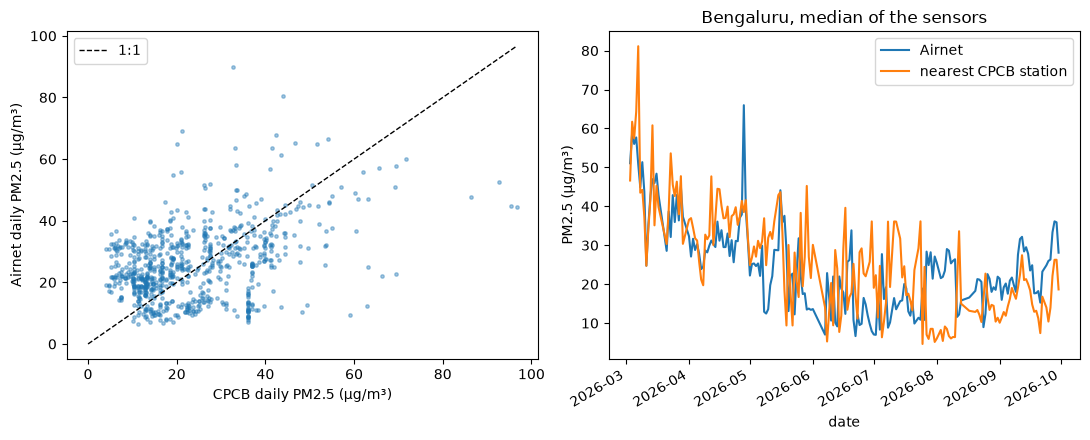

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].scatter(paired.reference, paired.pm25, s=6, alpha=0.4)
top = paired[["reference", "pm25"]].max().max()
axes[0].plot([0, top], [0, top], "k--", lw=1, label="1:1")
axes[0].set_xlabel("CPCB daily PM2.5 (µg/m³)")
axes[0].set_ylabel("Airnet daily PM2.5 (µg/m³)")
axes[0].legend()
city = paired.groupby("date")[["pm25", "reference"]].median()
city.index = pd.to_datetime(city.index)
city.plot(ax=axes[1])
axes[1].set_ylabel("PM2.5 (µg/m³)")
axes[1].set_title("Bengaluru, median of the sensors")
axes[1].legend(["Airnet", "nearest CPCB station"])
plt.tight_layout()
plt.show()

### Results with OAQ's daily records

The same sensor-days with OAQ's daily records in place of the daily means:

In [11]:
recs = oaq.daily_records("airnet", pairs.sensor_id, [2026])[
    ["sensor_id", "date", "pm25"]
]
both = paired.merge(
    recs.rename(columns={"pm25": "record"}), on=["sensor_id", "date"]
).dropna(subset=["record"])
pd.DataFrame(
    {
        "Airnet value": ["daily mean of the 15-minute readings", "OAQ daily record"],
        "r with CPCB": [
            both.pm25.corr(both.reference),
            both.record.corr(both.reference),
        ],
        "median |Airnet - CPCB|": [
            (both.pm25 - both.reference).abs().median(),
            (both.record - both.reference).abs().median(),
        ],
        "sensor-days": [len(both)] * 2,
    }
).round(2)

,Airnet value,r with CPCB,median |Airnet - CPCB|,sensor-days
0,daily mean of the 15-minute readings,0.40,9.62,770
1,OAQ daily record,0.33,10.11,770


## Summary

The tables above give the numbers. A new run of the notebook updates them.

- The low-cost OAQ sensors are Airnet's in Bengaluru and Aurassure's in smaller cities. Several of these cities have no CPCB station (section 1).
- The first-day table in section 2 gives the history of each provider.
- Section 2 gives the plausibility flags. It also lists the sensors with temperatures above 50 °C.
- OAQ's daily records usually equal the last 15-minute reading of the day, not the mean. But OAQ's 15-minute readings of the CPCB copy equal CPCB's own data (section 3). Use `readings_mean` or `daily_means` for daily values.
- For Airnet vs CPCB, see the accuracy table and plots in section 4. For completeness, precision and humidity, see the quality notebook.